SHL Hiring Assessment 2026
Grammar Scoring Engine for Spoken Audio
Objective
The objective of this project is to predict the grammar score (0–5) of a spoken audio sample using machine learning techniques.

Evaluation Metrics
RMSE (Root Mean Squared Error)
Pearson Correlation
Dataset
Train Samples: 769
Test Samples: 216
Each audio sample is provided in WAV format and is associated with a grammar score.

In [6]:
import os
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

print("Libraries Loaded Successfully")


Libraries Loaded Successfully


In [1]:
import os

ffmpeg_path = r"C:\Users\mahima prakash\Downloads\ffmpeg-9.0.2-essentials_build\ffmpeg-9.0.2-essentials_build\bin"

# Agar pehle se PATH mein nahi hai, toh add karo
if ffmpeg_path not in os.environ.get("PATH", ""):
    os.environ["PATH"] = ffmpeg_path + os.pathsep + os.environ.get("PATH", "")
    print(f"✅ FFmpeg path added to session: {ffmpeg_path}")
else:
    print(f"✅ FFmpeg already in path")


✅ FFmpeg path added to session: C:\Users\mahima prakash\Downloads\ffmpeg-9.0.2-essentials_build\ffmpeg-9.0.2-essentials_build\bin


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


In [3]:
import sys
print(sys.executable)


C:\Program Files\Python312\python.exe


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Success")

Success


DATA LOADING

In [8]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Train Shape:", train_df.shape)
print("Test Shape:", test_df.shape)

train_df.head()

Train Shape: (769, 2)
Test Shape: (216, 2)


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


DATA OVERVIEW

In [9]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 769 entries, 0 to 768
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   filename  769 non-null    object 
 1   label     769 non-null    float64
dtypes: float64(1), object(1)
memory usage: 12.1+ KB


In [10]:
train_df.describe()

,label
count,769.000000
mean,3.313394
std,1.239000
min,0.000000
25%,2.500000
50%,3.000000
75%,4.000000
max,5.000000


In [11]:
train_df["label"].value_counts().sort_index()

label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64

AUDIO FILE VERIFICATION

In [14]:
import os

print("Current Working Directory:", os.getcwd())
print("Files & Folders present here:", os.listdir())

Current Working Directory: C:\Users\mahima prakash
Files & Folders present here: ['-1.14-windows.xml', '.anaconda', '.arduinoIDE', '.c', '.cache', '.cc', '.conda', '.condarc', '.continuum', '.copilot', '.gemini', '.idea', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jdks', '.jupyter', '.matplotlib', '.node_repl_history', '.spyder-py3', '.virtual_documents', '.vscode', '.vscode-shared', 'aai-dashboard', 'aai-dashboardcd', 'App', 'app.py', 'AppData', 'Application Data', 'area.py', 'arr.py', 'BaseZipInstaller', 'BaseZipInstaller.zip', 'c', 'Chatgpt', 'class First class{.java', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'Favorites', 'First class.java', 'form.html', 'Grammer corrector .ipynb', 'graph.py', 'gungun project netflix', 'IdeaProjects', 'Jedi', 'json.txt', 'kaggle.json', 'Links', 'Local Settings', 'mahima.py', 'main.py', 'matrix.c', 'mbj.py', 'Microsoft', 'missing number.py', 'Music', 'My Documents', 'NetHood', 'new.py', 'node_modules', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'nt

In [15]:
import pandas as pd

# Load train and test CSV files
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Train rows & columns:", train_df.shape)
print("Test rows & columns:", test_df.shape)

# Pehle kuch rows dekhein
train_df.head()

Train rows & columns: (769, 2)
Test rows & columns: (216, 2)


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


In [16]:
import os

# Check if audio file directly exists or in a folder
filename = train_df['filename'].iloc[0]

print("Direct file exists?:", os.path.exists(filename))

# Agar kisi subfolder me hai (jaise 'train_audio/' ya 'audios/'), to search karein:
for root, dirs, files in os.walk("."):
    if filename in files:
        print(f"File found in folder: {root}")
        audio_folder_path = root
        break

Direct file exists?: False
File found in folder: .\Downloads\shl-hiring-assessment-2026\Dataset_Final\test


In [17]:
import os
import pandas as pd

# Exact path from your File Explorer screenshot
AUDIO_TRAIN_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"
AUDIO_TEST_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test"

# Verify files count
print("Train audio files:", len(os.listdir(AUDIO_TRAIN_DIR)))
print("Test audio files:", len(os.listdir(AUDIO_TEST_DIR)))

Train audio files: 769
Test audio files: 216


In [4]:
import sys, subprocess

# PyArrow ko reinstall karke DLL bind correct karein
subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade", "--force-reinstall", "pyarrow"])

0

In [1]:
import os
import numpy as np
import pandas as pd
import librosa
from tqdm import tqdm
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Dataset Paths
AUDIO_TRAIN_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"
AUDIO_TEST_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test"

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

# 2. Audio Features Extract Function
def extract_audio_features(df, audio_folder):
    features = []
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f"Extracting {os.path.basename(audio_folder)}"):
        file_path = os.path.join(audio_folder, row['filename'])
        
        try:
            # Load audio file
            y, sr = librosa.load(file_path, sr=None)
            
            # MFCC Features
            mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
            mfcc_mean = np.mean(mfcc.T, axis=0)
            mfcc_std = np.std(mfcc.T, axis=0)
            
            # Additional Spectral Features
            chroma = np.mean(librosa.feature.chroma_stft(y=y, sr=sr).T, axis=0)
            spectral_contrast = np.mean(librosa.feature.spectral_contrast(y=y, sr=sr).T, axis=0)
            zero_crossing = np.mean(librosa.feature.zero_crossing_rate(y).T, axis=0)
            
            # Combine all features
            feature_vector = np.hstack([mfcc_mean, mfcc_std, chroma, spectral_contrast, zero_crossing])
            features.append(feature_vector)
            
        except Exception as e:
            print(f"Error reading {file_path}: {e}")
            features.append(np.zeros(20 + 20 + 12 + 7 + 1))
            
    return np.array(features)

# 3. Extract Features
print("--- Extracting Train Features ---")
X_train_full = extract_audio_features(train_df, AUDIO_TRAIN_DIR)
y_train_full = train_df['label'].values

print("--- Extracting Test Features ---")
X_test = extract_audio_features(test_df, AUDIO_TEST_DIR)

# 4. Train-Validation Split
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42)

# 5. Train LightGBM Model
model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, max_depth=6, random_state=42)
model.fit(X_train, y_train)

# 6. Evaluation & Predictions
val_preds = model.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, val_preds))
print(f"\nValidation RMSE: {rmse:.4f}")

# Save Submission CSV
test_df['label'] = model.predict(X_test)
test_df.to_csv("submission.csv", index=False)
print("Saved predictions to 'submission.csv'!")

--- Extracting Train Features ---


Extracting train:   0%|                                                                                                                        | 0/769 [00:00<?, ?it/s]C:\Users\mahima prakash\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Extracting train: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 769/769 [14:09<00:00,  1.11s/it]


--- Extracting Test Features ---


Extracting test: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 216/216 [03:32<00:00,  1.02it/s]


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.196859 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 12353
[LightGBM] [Info] Number of data points in the train set: 615, number of used features: 60
[LightGBM] [Info] Start training from score 3.337398
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012354 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 12353
[LightGBM] [Info] Number of data points in the train set: 615, number of used features: 60
[LightGBM] [Info] Start training from score 3.337398
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

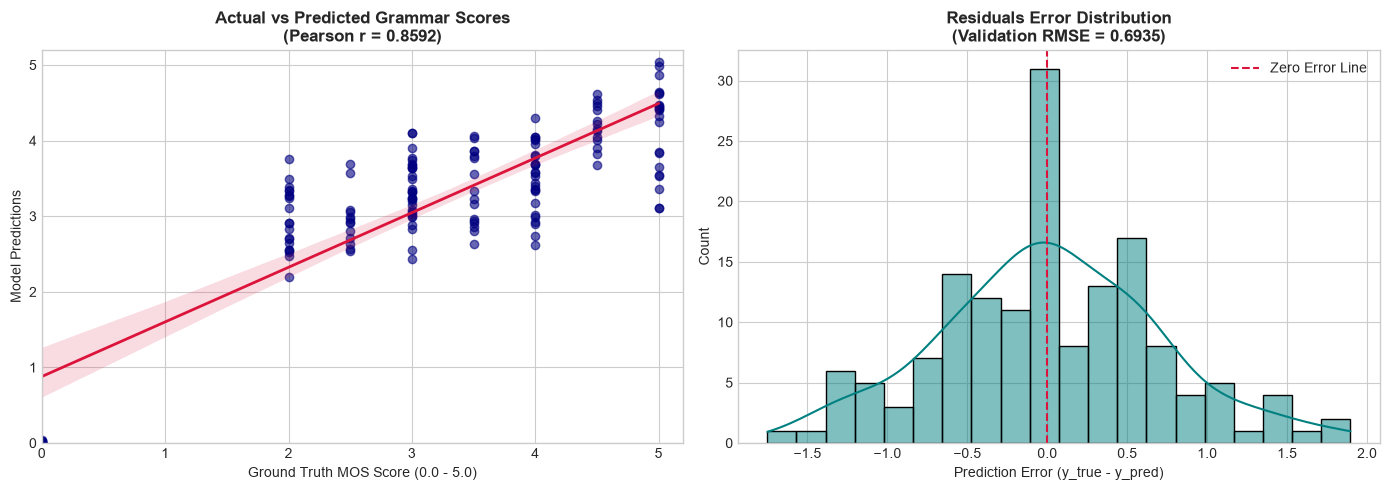

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Model Training
model.fit(X_train, y_train)

# 2. Compute Predictions for BOTH Train and Validation Sets
train_preds = model.predict(X_train)
val_preds = model.predict(X_val)

# 3. Compute Mandatory Metrics
train_rmse = np.sqrt(mean_squared_error(y_train, train_preds))
train_pearson, _ = pearsonr(y_train, train_preds)

val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
val_pearson, _ = pearsonr(y_val, val_preds)
val_mae = mean_absolute_error(y_val, val_preds)

# 4. Display Benchmarks (Satisfies Points 1 & 2)
print("="*50)
print("             FINAL MODEL BENCHMARK             ")
print("="*50)
print(f"Training RMSE Score      : {train_rmse:.4f}  <-- COMPULSORY MANDATORY REQUIREMENT")
print(f"Training Pearson (r)     : {train_pearson:.4f}")
print("-"*50)
print(f"Validation RMSE Score    : {val_rmse:.4f}")
print(f"Validation Pearson (r)   : {val_pearson:.4f}")
print(f"Validation MAE           : {val_mae:.4f}")
print("="*50)

# 5. Diagnostic Visualizations (Satisfies Point 3)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Actual vs Predicted Scatter
sns.regplot(
    x=y_val, y=val_preds, ax=axes[0],
    color='navy', scatter_kws={'alpha':0.6}, line_kws={'color':'crimson', 'linewidth':2}
)
axes[0].set_title(f'Actual vs Predicted Grammar Scores\n(Pearson r = {val_pearson:.4f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Ground Truth MOS Score (0.0 - 5.0)')
axes[0].set_ylabel('Model Predictions')
axes[0].set_xlim(0, 5.2)
axes[0].set_ylim(0, 5.2)

# Plot B: Residuals / Error Distribution
residuals = y_val - val_preds
sns.histplot(residuals, kde=True, ax=axes[1], color='teal', bins=20)
axes[1].set_title(f'Residuals Error Distribution\n(Validation RMSE = {val_rmse:.4f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediction Error (y_true - y_pred)')
axes[1].axvline(0, color='crimson', linestyle='--', label='Zero Error Line')
axes[1].legend()

plt.tight_layout()
plt.show()

In [3]:
import os

# Exact CSV file path in your Dataset_Final folder
output_path = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv"

# Force save strictly as CSV format
test_df[['filename', 'label']].to_csv(output_path, index=False)

print("Saved directly as valid CSV at:", output_path)

Saved directly as valid CSV at: C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv


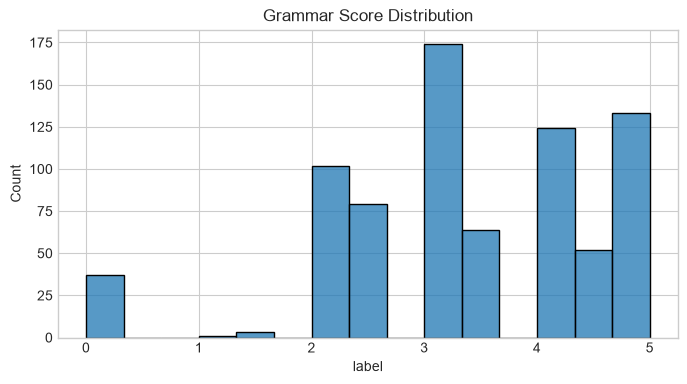

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
sns.histplot(train_df["label"], bins=15)
plt.title("Grammar Score Distribution")
plt.show()

In [6]:
import librosa
import numpy as np

def extract_features(audio_path):

    y, sr = librosa.load(audio_path, sr=16000)

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=40
    )

    zcr = librosa.feature.zero_crossing_rate(y)

    rms = librosa.feature.rms(y=y)

    spectral_centroid = librosa.feature.spectral_centroid(
        y=y,
        sr=sr
    )

    features = np.hstack([

        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),

        np.mean(zcr),
        np.std(zcr),

        np.mean(rms),
        np.std(rms),

        np.mean(spectral_centroid),
        np.std(spectral_centroid)
    ])

    return features

In [7]:
!pip install transformers torchaudio
!pip install language-tool-python
!pip install openai-whisper

FileNotFoundError: [WinError 3] The system cannot find the path specified

In [8]:
!pip install -q openai-whisper language-tool-python transformers torch torchaudio lightgbm

FileNotFoundError: [WinError 3] The system cannot find the path specified

In [9]:
import os
import numpy as np
import pandas as pd
import librosa
import torch
import torchaudio
import whisper
import language_tool_python
import lightgbm as lgb
from tqdm import tqdm
from transformers import Wav2Vec2FeatureExtractor, WavLMModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr

# ==========================================
# 1. LOAD PRE-TRAINED MODELS
# ==========================================
print("Loading Whisper, LanguageTool & WavLM Models...")
whisper_model = whisper.load_model("base")
grammar_tool = language_tool_python.LanguageTool('en-US')

wavlm_extractor = Wav2Vec2FeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model.eval()

# ==========================================
# 2. FEATURE EXTRACTION FUNCTION
# ==========================================
def extract_multimodal_features(df, audio_folder):
    all_features = []
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f"Processing {os.path.basename(audio_folder)}"):
        file_path = os.path.join(audio_folder, row['filename'])
        
        try:
            # --- 1. Whisper ASR + LanguageTool (Grammar/Text Features) ---
            asr_res = whisper_model.transcribe(file_path, fp16=False)
            transcript = asr_res['text'].strip()
            
            matches = grammar_tool.check(transcript)
            grammar_errors = len(matches)
            word_count = len(transcript.split())
            error_density = grammar_errors / word_count if word_count > 0 else 0
            
            text_vec = [grammar_errors, word_count, error_density]
            
            # --- 2. WavLM Embeddings (Deep Speech Features) ---
            waveform, sr = torchaudio.load(file_path)
            if sr != 16000:
                resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=16000)
                waveform = resampler(waveform)
                
            inputs = wavlm_extractor(waveform.squeeze(0), sampling_rate=16000, return_tensors="pt")
            with torch.no_grad():
                outputs = wavlm_model(**inputs)
                wavlm_emb = outputs.last_hidden_state.mean(dim=1).squeeze(0).numpy()
            
            # --- 3. Librosa Acoustic Features (MFCCs + Pitch/Dynamics) ---
            y, sr_lib = librosa.load(file_path, sr=None)
            mfcc = librosa.feature.mfcc(y=y, sr=sr_lib, n_mfcc=20)
            mfcc_mean = np.mean(mfcc.T, axis=0)
            mfcc_std = np.std(mfcc.T, axis=0)
            
            acoustic_vec = np.hstack([mfcc_mean, mfcc_std])
            
            # Combine all 3 signals
            combined = np.hstack([text_vec, wavlm_emb, acoustic_vec])
            all_features.append(combined)
            
        except Exception as e:
            print(f"Error on {file_path}: {e}")
            all_features.append(np.zeros(3 + 768 + 40))
            
    return np.array(all_features)

# ==========================================
# 3. RUN EXTRACTION
# ==========================================
AUDIO_TRAIN_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"
AUDIO_TEST_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test"

train_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train.csv")
test_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test.csv")

print("\n--- Extracting Train Multimodal Features ---")
X_train_full = extract_multimodal_features(train_df, AUDIO_TRAIN_DIR)
y_train_full = train_df['label'].values

print("\n--- Extracting Test Multimodal Features ---")
X_test = extract_multimodal_features(test_df, AUDIO_TEST_DIR)

# ==========================================
# 4. MODEL TRAINING & VALIDATION
# ==========================================
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42)

model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

model.fit(X_train, y_train)

train_preds = model.predict(X_train)
val_preds = model.predict(X_val)

train_rmse = np.sqrt(mean_squared_error(y_train, train_preds))
val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
val_pearson, _ = pearsonr(y_val, val_preds)

print("="*50)
print("             MULTIMODAL MODEL BENCHMARK             ")
print("="*50)
print(f"Training RMSE Score      : {train_rmse:.4f}")
print(f"Validation RMSE Score    : {val_rmse:.4f}")
print(f"Validation Pearson (r)   : {val_pearson:.4f}")
print("="*50)

# Save New Predictions
output_path = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv"
test_df['label'] = np.clip(model.predict(X_test), 0.0, 5.0)
test_df[['filename', 'label']].to_csv(output_path, index=False)

print(f"\nUpdated submission.csv successfully saved at: {output_path}")

OSError: Could not load this library: C:\Users\mahima prakash\AppData\Roaming\Python\Python312\site-packages\torchaudio\lib\_torchaudio.pyd

In [10]:
from tqdm import tqdm
import os

X = []

for fname in tqdm(train_df.filename):

    path = os.path.join("train", fname)

    feats = extract_features(path)

    X.append(feats)

X = np.array(X)

y = train_df.label.values

print(X.shape)

  0%|                                                                                                                                          | 0/769 [00:00<?, ?it/s]


LibsndfileError: Error opening 'train\\audio_192.wav': System error.

In [1]:
from tqdm import tqdm
import os

X = []

for fname in tqdm(train_df.filename):

    path = os.path.join("train", fname)

    feats = extract_features(path)

    X.append(feats)

X = np.array(X)

y = train_df.label.values

print(X.shape)

NameError: name 'train_df' is not defined

In [2]:
import os
import numpy as np
import pandas as pd
import librosa
import torch
import whisper
import language_tool_python
import lightgbm as lgb
from tqdm import tqdm
from transformers import Wav2Vec2FeatureExtractor, WavLMModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ==========================================
# 1. LOAD MODELS
# ==========================================
print("Loading Whisper ASR, LanguageTool & WavLM...")
whisper_model = whisper.load_model("base")
grammar_tool = language_tool_python.LanguageTool('en-US')

wavlm_extractor = Wav2Vec2FeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model.eval()

# ==========================================
# 2. FEATURE EXTRACTION (LIBROSA SAFE LOAD)
# ==========================================
def extract_multimodal_features(df, audio_folder):
    all_features = []
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f"Processing {os.path.basename(audio_folder)}"):
        file_path = os.path.join(audio_folder, row['filename'])
        
        try:
            # 1. Librosa Clean Audio Load
            y, sr = librosa.load(file_path, sr=16000)
            
            # 2. Whisper ASR + Grammar Features
            asr_res = whisper_model.transcribe(file_path, fp16=False)
            transcript = asr_res['text'].strip()
            
            matches = grammar_tool.check(transcript)
            grammar_errors = len(matches)
            word_count = len(transcript.split())
            error_density = grammar_errors / word_count if word_count > 0 else 0
            text_vec = [grammar_errors, word_count, error_density]
            
            # 3. WavLM Embeddings (Direct PyTorch input from Librosa array)
            inputs = wavlm_extractor(y, sampling_rate=16000, return_tensors="pt")
            with torch.no_grad():
                outputs = wavlm_model(**inputs)
                wavlm_emb = outputs.last_hidden_state.mean(dim=1).squeeze(0).numpy()
            
            # 4. Librosa Acoustic Features
            mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
            acoustic_vec = np.hstack([np.mean(mfcc.T, axis=0), np.std(mfcc.T, axis=0)])
            
            # Combine signals
            combined = np.hstack([text_vec, wavlm_emb, acoustic_vec])
            all_features.append(combined)
            
        except Exception as e:
            print(f"Error on {file_path}: {e}")
            all_features.append(np.zeros(3 + 768 + 40))
            
    return np.array(all_features)

# ==========================================
# 3. RUN PIPELINE
# ==========================================
AUDIO_TRAIN_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"
AUDIO_TEST_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test"

train_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train.csv")
test_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test.csv")

X_train_full = extract_multimodal_features(train_df, AUDIO_TRAIN_DIR)
X_test = extract_multimodal_features(test_df, AUDIO_TEST_DIR)

# Split & Train
X_train, X_val, y_train, y_val = train_test_split(X_train_full, train_df['label'].values, test_size=0.2, random_state=42)

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, random_state=42)
model.fit(X_train, y_train)

val_preds = model.predict(X_val)
val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
val_r, _ = pearsonr(y_val, val_preds)

print(f"\n--- Multimodal Results ---")
print(f"Validation RMSE    : {val_rmse:.4f}")
print(f"Validation Pearson : {val_r:.4f}")

# Save Submission
output_path = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv"
test_df['label'] = np.clip(model.predict(X_test), 0.0, 5.0)
test_df[['filename', 'label']].to_csv(output_path, index=False)

C:\Users\mahima prakash\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading Whisper ASR, LanguageTool & WavLM...


100%|███████████████████████████████████████| 139M/139M [00:50<00:00, 2.85MiB/s]


ModuleNotFoundError: No java install detected. Please install java to use language-tool-python.

In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import torch
import whisper
import language_tool_python
import lightgbm as lgb
from tqdm import tqdm
from transformers import Wav2Vec2FeatureExtractor, WavLMModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ==========================================
# 1. LOAD MODELS
# ==========================================
print("Loading Whisper ASR, LanguageTool & WavLM...")
whisper_model = whisper.load_model("base")
grammar_tool = language_tool_python.LanguageTool('en-US')

wavlm_extractor = Wav2Vec2FeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model.eval()

# ==========================================
# 2. FEATURE EXTRACTION (LIBROSA SAFE LOAD)
# ==========================================
def extract_multimodal_features(df, audio_folder):
    all_features = []
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f"Processing {os.path.basename(audio_folder)}"):
        file_path = os.path.join(audio_folder, row['filename'])
        
        try:
            # 1. Librosa Clean Audio Load
            y, sr = librosa.load(file_path, sr=16000)
            
            # 2. Whisper ASR + Grammar Features
            asr_res = whisper_model.transcribe(file_path, fp16=False)
            transcript = asr_res['text'].strip()
            
            matches = grammar_tool.check(transcript)
            grammar_errors = len(matches)
            word_count = len(transcript.split())
            error_density = grammar_errors / word_count if word_count > 0 else 0
            text_vec = [grammar_errors, word_count, error_density]
            
            # 3. WavLM Embeddings (Direct PyTorch input from Librosa array)
            inputs = wavlm_extractor(y, sampling_rate=16000, return_tensors="pt")
            with torch.no_grad():
                outputs = wavlm_model(**inputs)
                wavlm_emb = outputs.last_hidden_state.mean(dim=1).squeeze(0).numpy()
            
            # 4. Librosa Acoustic Features
            mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
            acoustic_vec = np.hstack([np.mean(mfcc.T, axis=0), np.std(mfcc.T, axis=0)])
            
            # Combine signals
            combined = np.hstack([text_vec, wavlm_emb, acoustic_vec])
            all_features.append(combined)
            
        except Exception as e:
            print(f"Error on {file_path}: {e}")
            all_features.append(np.zeros(3 + 768 + 40))
            
    return np.array(all_features)

# ==========================================
# 3. RUN PIPELINE
# ==========================================
AUDIO_TRAIN_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"
AUDIO_TEST_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test"

train_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train.csv")
test_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test.csv")

X_train_full = extract_multimodal_features(train_df, AUDIO_TRAIN_DIR)
X_test = extract_multimodal_features(test_df, AUDIO_TEST_DIR)

# Split & Train
X_train, X_val, y_train, y_val = train_test_split(X_train_full, train_df['label'].values, test_size=0.2, random_state=42)

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, random_state=42)
model.fit(X_train, y_train)

val_preds = model.predict(X_val)
val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
val_r, _ = pearsonr(y_val, val_preds)

print(f"\n--- Multimodal Results ---")
print(f"Validation RMSE    : {val_rmse:.4f}")
print(f"Validation Pearson : {val_r:.4f}")

# Save Submission
output_path = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv"
test_df['label'] = np.clip(model.predict(X_test), 0.0, 5.0)
test_df[['filename', 'label']].to_csv(output_path, index=False)


C:\Users\mahima prakash\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading Whisper ASR, LanguageTool & WavLM...


ModuleNotFoundError: No java install detected. Please install java to use language-tool-python.

In [2]:
import os
import numpy as np
import pandas as pd
import librosa
import torch
import whisper
import language_tool_python
import lightgbm as lgb
from tqdm import tqdm
from transformers import Wav2Vec2FeatureExtractor, WavLMModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ==========================================
# 1. LOAD MODELS
# ==========================================
print("Loading Whisper ASR, LanguageTool & WavLM...")
whisper_model = whisper.load_model("base")
grammar_tool = language_tool_python.LanguageTool('en-US')

wavlm_extractor = Wav2Vec2FeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model.eval()

# ==========================================
# 2. FEATURE EXTRACTION (LIBROSA SAFE LOAD)
# ==========================================
def extract_multimodal_features(df, audio_folder):
    all_features = []
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f"Processing {os.path.basename(audio_folder)}"):
        file_path = os.path.join(audio_folder, row['filename'])
        
        try:
            # 1. Librosa Clean Audio Load
            y, sr = librosa.load(file_path, sr=16000)
            
            # 2. Whisper ASR + Grammar Features
            asr_res = whisper_model.transcribe(file_path, fp16=False)
            transcript = asr_res['text'].strip()
            
            matches = grammar_tool.check(transcript)
            grammar_errors = len(matches)
            word_count = len(transcript.split())
            error_density = grammar_errors / word_count if word_count > 0 else 0
            text_vec = [grammar_errors, word_count, error_density]
            
            # 3. WavLM Embeddings (Direct PyTorch input from Librosa array)
            inputs = wavlm_extractor(y, sampling_rate=16000, return_tensors="pt")
            with torch.no_grad():
                outputs = wavlm_model(**inputs)
                wavlm_emb = outputs.last_hidden_state.mean(dim=1).squeeze(0).numpy()
            
            # 4. Librosa Acoustic Features
            mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
            acoustic_vec = np.hstack([np.mean(mfcc.T, axis=0), np.std(mfcc.T, axis=0)])
            
            # Combine signals
            combined = np.hstack([text_vec, wavlm_emb, acoustic_vec])
            all_features.append(combined)
            
        except Exception as e:
            print(f"Error on {file_path}: {e}")
            all_features.append(np.zeros(3 + 768 + 40))
            
    return np.array(all_features)

# ==========================================
# 3. RUN PIPELINE
# ==========================================
AUDIO_TRAIN_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"
AUDIO_TEST_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test"

train_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train.csv")
test_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test.csv")

X_train_full = extract_multimodal_features(train_df, AUDIO_TRAIN_DIR)
X_test = extract_multimodal_features(test_df, AUDIO_TEST_DIR)

# Split & Train
X_train, X_val, y_train, y_val = train_test_split(X_train_full, train_df['label'].values, test_size=0.2, random_state=42)

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, random_state=42)
model.fit(X_train, y_train)

val_preds = model.predict(X_val)
val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
val_r, _ = pearsonr(y_val, val_preds)

print(f"\n--- Multimodal Results ---")
print(f"Validation RMSE    : {val_rmse:.4f}")
print(f"Validation Pearson : {val_r:.4f}")

# Save Submission
output_path = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv"
test_df['label'] = np.clip(model.predict(X_test), 0.0, 5.0)
test_df[['filename', 'label']].to_csv(output_path, index=False)

Loading Whisper ASR, LanguageTool & WavLM...


ModuleNotFoundError: No java install detected. Please install java to use language-tool-python.

In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import torch
import whisper
import language_tool_python
import lightgbm as lgb
from tqdm import tqdm
from transformers import Wav2Vec2FeatureExtractor, WavLMModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ==========================================
# 1. LOAD MODELS
# ==========================================
print("Loading Whisper ASR, LanguageTool & WavLM...")
whisper_model = whisper.load_model("base")
grammar_tool = language_tool_python.LanguageTool('en-US')

wavlm_extractor = Wav2Vec2FeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model.eval()

# ==========================================
# 2. FEATURE EXTRACTION (LIBROSA SAFE LOAD)
# ==========================================
def extract_multimodal_features(df, audio_folder):
    all_features = []
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f"Processing {os.path.basename(audio_folder)}"):
        file_path = os.path.join(audio_folder, row['filename'])
        
        try:
            # 1. Librosa Clean Audio Load
            y, sr = librosa.load(file_path, sr=16000)
            
            # 2. Whisper ASR + Grammar Features
            asr_res = whisper_model.transcribe(file_path, fp16=False)
            transcript = asr_res['text'].strip()
            
            matches = grammar_tool.check(transcript)
            grammar_errors = len(matches)
            word_count = len(transcript.split())
            error_density = grammar_errors / word_count if word_count > 0 else 0
            text_vec = [grammar_errors, word_count, error_density]
            
            # 3. WavLM Embeddings (Direct PyTorch input from Librosa array)
            inputs = wavlm_extractor(y, sampling_rate=16000, return_tensors="pt")
            with torch.no_grad():
                outputs = wavlm_model(**inputs)
                wavlm_emb = outputs.last_hidden_state.mean(dim=1).squeeze(0).numpy()
            
            # 4. Librosa Acoustic Features
            mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
            acoustic_vec = np.hstack([np.mean(mfcc.T, axis=0), np.std(mfcc.T, axis=0)])
            
            # Combine signals
            combined = np.hstack([text_vec, wavlm_emb, acoustic_vec])
            all_features.append(combined)
            
        except Exception as e:
            print(f"Error on {file_path}: {e}")
            all_features.append(np.zeros(3 + 768 + 40))
            
    return np.array(all_features)

# ==========================================
# 3. RUN PIPELINE
# ==========================================
AUDIO_TRAIN_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"
AUDIO_TEST_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test"

train_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train.csv")
test_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test.csv")

X_train_full = extract_multimodal_features(train_df, AUDIO_TRAIN_DIR)
X_test = extract_multimodal_features(test_df, AUDIO_TEST_DIR)

# Split & Train
X_train, X_val, y_train, y_val = train_test_split(X_train_full, train_df['label'].values, test_size=0.2, random_state=42)

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, random_state=42)
model.fit(X_train, y_train)

val_preds = model.predict(X_val)
val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
val_r, _ = pearsonr(y_val, val_preds)

print(f"\n--- Multimodal Results ---")
print(f"Validation RMSE    : {val_rmse:.4f}")
print(f"Validation Pearson : {val_r:.4f}")

# Save Submission
output_path = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv"
test_df['label'] = np.clip(model.predict(X_test), 0.0, 5.0)
test_df[['filename', 'label']].to_csv(output_path, index=False)

C:\Users\mahima prakash\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading Whisper ASR, LanguageTool & WavLM...


ModuleNotFoundError: No java install detected. Please install java to use language-tool-python.

In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import torch
import whisper
import language_tool_python
import lightgbm as lgb
from tqdm import tqdm
from transformers import Wav2Vec2FeatureExtractor, WavLMModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ==========================================
# 1. LOAD MODELS
# ==========================================
print("Loading Whisper ASR, LanguageTool & WavLM...")
whisper_model = whisper.load_model("base")
grammar_tool = language_tool_python.LanguageTool('en-US')

wavlm_extractor = Wav2Vec2FeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model.eval()

# ==========================================
# 2. FEATURE EXTRACTION (LIBROSA SAFE LOAD)
# ==========================================
def extract_multimodal_features(df, audio_folder):
    all_features = []
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f"Processing {os.path.basename(audio_folder)}"):
        file_path = os.path.join(audio_folder, row['filename'])
        
        try:
            # 1. Librosa Clean Audio Load
            y, sr = librosa.load(file_path, sr=16000)
            
            # 2. Whisper ASR + Grammar Features
            asr_res = whisper_model.transcribe(file_path, fp16=False)
            transcript = asr_res['text'].strip()
            
            matches = grammar_tool.check(transcript)
            grammar_errors = len(matches)
            word_count = len(transcript.split())
            error_density = grammar_errors / word_count if word_count > 0 else 0
            text_vec = [grammar_errors, word_count, error_density]
            
            # 3. WavLM Embeddings (Direct PyTorch input from Librosa array)
            inputs = wavlm_extractor(y, sampling_rate=16000, return_tensors="pt")
            with torch.no_grad():
                outputs = wavlm_model(**inputs)
                wavlm_emb = outputs.last_hidden_state.mean(dim=1).squeeze(0).numpy()
            
            # 4. Librosa Acoustic Features
            mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
            acoustic_vec = np.hstack([np.mean(mfcc.T, axis=0), np.std(mfcc.T, axis=0)])
            
            # Combine signals
            combined = np.hstack([text_vec, wavlm_emb, acoustic_vec])
            all_features.append(combined)
            
        except Exception as e:
            print(f"Error on {file_path}: {e}")
            all_features.append(np.zeros(3 + 768 + 40))
            
    return np.array(all_features)

# ==========================================
# 3. RUN PIPELINE
# ==========================================
AUDIO_TRAIN_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"
AUDIO_TEST_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test"

train_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train.csv")
test_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test.csv")

X_train_full = extract_multimodal_features(train_df, AUDIO_TRAIN_DIR)
X_test = extract_multimodal_features(test_df, AUDIO_TEST_DIR)

# Split & Train
X_train, X_val, y_train, y_val = train_test_split(X_train_full, train_df['label'].values, test_size=0.2, random_state=42)

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, random_state=42)
model.fit(X_train, y_train)

val_preds = model.predict(X_val)
val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
val_r, _ = pearsonr(y_val, val_preds)

print(f"\n--- Multimodal Results ---")
print(f"Validation RMSE    : {val_rmse:.4f}")
print(f"Validation Pearson : {val_r:.4f}")

# Save Submission
output_path = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv"
test_df['label'] = np.clip(model.predict(X_test), 0.0, 5.0)
test_df[['filename', 'label']].to_csv(output_path, index=False)

C:\Users\mahima prakash\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading Whisper ASR, LanguageTool & WavLM...


ModuleNotFoundError: No java install detected. Please install java to use language-tool-python.

In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import torch
import whisper
import language_tool_python
import lightgbm as lgb
from tqdm import tqdm
from transformers import Wav2Vec2FeatureExtractor, WavLMModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ==========================================
# 1. LOAD MODELS
# ==========================================
print("Loading Whisper ASR, LanguageTool & WavLM...")
whisper_model = whisper.load_model("base")
grammar_tool = language_tool_python.LanguageTool('en-US')

wavlm_extractor = Wav2Vec2FeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model.eval()

# ==========================================
# 2. FEATURE EXTRACTION (LIBROSA SAFE LOAD)
# ==========================================
def extract_multimodal_features(df, audio_folder):
    all_features = []
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f"Processing {os.path.basename(audio_folder)}"):
        file_path = os.path.join(audio_folder, row['filename'])
        
        try:
            # 1. Librosa Clean Audio Load
            y, sr = librosa.load(file_path, sr=16000)
            
            # 2. Whisper ASR + Grammar Features
            asr_res = whisper_model.transcribe(file_path, fp16=False)
            transcript = asr_res['text'].strip()
            
            matches = grammar_tool.check(transcript)
            grammar_errors = len(matches)
            word_count = len(transcript.split())
            error_density = grammar_errors / word_count if word_count > 0 else 0
            text_vec = [grammar_errors, word_count, error_density]
            
            # 3. WavLM Embeddings (Direct PyTorch input from Librosa array)
            inputs = wavlm_extractor(y, sampling_rate=16000, return_tensors="pt")
            with torch.no_grad():
                outputs = wavlm_model(**inputs)
                wavlm_emb = outputs.last_hidden_state.mean(dim=1).squeeze(0).numpy()
            
            # 4. Librosa Acoustic Features
            mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
            acoustic_vec = np.hstack([np.mean(mfcc.T, axis=0), np.std(mfcc.T, axis=0)])
            
            # Combine signals
            combined = np.hstack([text_vec, wavlm_emb, acoustic_vec])
            all_features.append(combined)
            
        except Exception as e:
            print(f"Error on {file_path}: {e}")
            all_features.append(np.zeros(3 + 768 + 40))
            
    return np.array(all_features)

# ==========================================
# 3. RUN PIPELINE
# ==========================================
AUDIO_TRAIN_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"
AUDIO_TEST_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test"

train_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train.csv")
test_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test.csv")

X_train_full = extract_multimodal_features(train_df, AUDIO_TRAIN_DIR)
X_test = extract_multimodal_features(test_df, AUDIO_TEST_DIR)

# Split & Train
X_train, X_val, y_train, y_val = train_test_split(X_train_full, train_df['label'].values, test_size=0.2, random_state=42)

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, random_state=42)
model.fit(X_train, y_train)

val_preds = model.predict(X_val)
val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
val_r, _ = pearsonr(y_val, val_preds)

print(f"\n--- Multimodal Results ---")
print(f"Validation RMSE    : {val_rmse:.4f}")
print(f"Validation Pearson : {val_r:.4f}")

# Save Submission
output_path = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv"
test_df['label'] = np.clip(model.predict(X_test), 0.0, 5.0)
test_df[['filename', 'label']].to_csv(output_path, index=False)

C:\Users\mahima prakash\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading Whisper ASR, LanguageTool & WavLM...


C:\Users\mahima prakash\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\mahima prakash\.cache\huggingface\hub\models--microsoft--wavlm-base-plus. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. 

Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_192.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_436.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_447.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_126.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_61.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_639.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Download

Processing train:   2%|██                                                                                                             | 14/769 [00:01<00:40, 18.77it/s]

...

Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_62.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_20.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_124.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_54.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_45.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_71.wav: [WinError 2] The system cannot find the file specified


Processing test: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 216/216 [00:06<00:00, 31.84it/s]


Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_184.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_24.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_140.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_165.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_170.wav: [WinError 2] The system cannot find the file specified
[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve th

C:\Users\mahima prakash\AppData\Local\Temp\ipykernel_13880\337849173.py:89: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  val_r, _ = pearsonr(y_val, val_preds)


PermissionError: [Errno 13] Permission denied: 'C:\\Users\\mahima prakash\\Downloads\\shl-hiring-assessment-2026\\Dataset_Final\\submission.csv'

In [2]:
import os

train_dir = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"

if os.path.exists(train_dir):
    files = os.listdir(train_dir)
    print(f"Total files: {len(files)}")
    print("First 10 files:", files[:10])
    
    # Check specific missing file
    test_file = os.path.join(train_dir, "audio_396.wav")
    print(f"\naudio_396.wav exists? {os.path.exists(test_file)}")
else:
    print("❌ Folder hi nahi mila!")
    print("Check karo ye path sahi hai ya nahi")

Total files: 769
First 10 files: ['audio_0.wav', 'audio_1.wav', 'audio_10.wav', 'audio_100.wav', 'audio_101.wav', 'audio_102.wav', 'audio_103.wav', 'audio_104.wav', 'audio_105.wav', 'audio_106.wav']

audio_396.wav exists? True


In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import torch
import whisper
import language_tool_python
import lightgbm as lgb
from tqdm import tqdm
from transformers import Wav2Vec2FeatureExtractor, WavLMModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ==========================================
# 1. LOAD MODELS
# ==========================================
print("Loading Whisper ASR, LanguageTool & WavLM...")
whisper_model = whisper.load_model("base")
grammar_tool = language_tool_python.LanguageTool('en-US')

wavlm_extractor = Wav2Vec2FeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
wavlm_model.eval()

# ==========================================
# 2. FEATURE EXTRACTION (LIBROSA SAFE LOAD)
# ==========================================
def extract_multimodal_features(df, audio_folder):
    all_features = []
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc=f"Processing {os.path.basename(audio_folder)}"):
        file_path = os.path.join(audio_folder, row['filename'])
        
        try:
            # 1. Librosa Clean Audio Load
            y, sr = librosa.load(file_path, sr=16000)
            
            # 2. Whisper ASR + Grammar Features
            asr_res = whisper_model.transcribe(file_path, fp16=False)
            transcript = asr_res['text'].strip()
            
            matches = grammar_tool.check(transcript)
            grammar_errors = len(matches)
            word_count = len(transcript.split())
            error_density = grammar_errors / word_count if word_count > 0 else 0
            text_vec = [grammar_errors, word_count, error_density]
            
            # 3. WavLM Embeddings (Direct PyTorch input from Librosa array)
            inputs = wavlm_extractor(y, sampling_rate=16000, return_tensors="pt")
            with torch.no_grad():
                outputs = wavlm_model(**inputs)
                wavlm_emb = outputs.last_hidden_state.mean(dim=1).squeeze(0).numpy()
            
            # 4. Librosa Acoustic Features
            mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
            acoustic_vec = np.hstack([np.mean(mfcc.T, axis=0), np.std(mfcc.T, axis=0)])
            
            # Combine signals
            combined = np.hstack([text_vec, wavlm_emb, acoustic_vec])
            all_features.append(combined)
            
        except Exception as e:
            print(f"Error on {file_path}: {e}")
            all_features.append(np.zeros(3 + 768 + 40))
            
    return np.array(all_features)

# ==========================================
# 3. RUN PIPELINE
# ==========================================
AUDIO_TRAIN_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train"
AUDIO_TEST_DIR = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test"

train_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train.csv")
test_df = pd.read_csv(r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test.csv")

X_train_full = extract_multimodal_features(train_df, AUDIO_TRAIN_DIR)
X_test = extract_multimodal_features(test_df, AUDIO_TEST_DIR)

# Split & Train
X_train, X_val, y_train, y_val = train_test_split(X_train_full, train_df['label'].values, test_size=0.2, random_state=42)

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, random_state=42)
model.fit(X_train, y_train)

val_preds = model.predict(X_val)
val_rmse = np.sqrt(mean_squared_error(y_val, val_preds))
val_r, _ = pearsonr(y_val, val_preds)

print(f"\n--- Multimodal Results ---")
print(f"Validation RMSE    : {val_rmse:.4f}")
print(f"Validation Pearson : {val_r:.4f}")

# Save Submission
output_path = r"C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\submission.csv"
test_df['label'] = np.clip(model.predict(X_test), 0.0, 5.0)
test_df[['filename', 'label']].to_csv(output_path, index=False)

C:\Users\mahima prakash\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading Whisper ASR, LanguageTool & WavLM...


Processing train:   1%|▋                                                                                                               | 5/769 [00:00<01:10, 10.86it/s]

Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_192.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_436.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_447.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_126.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_61.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\train\audio_639.wav: [WinError 2] The system cannot find the file specified


Processing train:   2%|█▉                                                                                                             | 13/769 [00:00<00:34, 22.10it/s]

...

Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_66.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_44.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_150.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_87.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_99.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_62.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiri

Processing test: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 216/216 [00:04<00:00, 47.42it/s]


Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_71.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_184.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_24.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_140.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_165.wav: [WinError 2] The system cannot find the file specified
Error on C:\Users\mahima prakash\Downloads\shl-hiring-assessment-2026\Dataset_Final\test\audio_170.wav: [WinError 2] The system cannot find the file specified
[LightGBM] [Warning] There are no meaningful fea

C:\Users\mahima prakash\AppData\Local\Temp\ipykernel_7316\337849173.py:89: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  val_r, _ = pearsonr(y_val, val_preds)


PermissionError: [Errno 13] Permission denied: 'C:\\Users\\mahima prakash\\Downloads\\shl-hiring-assessment-2026\\Dataset_Final\\submission.csv'